# Learning curves

Why do the unified models stop so early and predict almost flat lines? These curves show training and stopping-slice loss at every step, with early stopping off, so they continue past where it would have stopped. They use the unified models and all 4 input sets on walk-forward rounds 1, 4 and 8, with 2 seeds. Only each round's known days are used, so scored days and the test split stay untouched.

Losses are divided by the baseline's loss on the same data, so **1 means no better than always predicting the training mean**, and below 1 beats it.

| What the curves show | What it means | What to try |
| --- | --- | --- |
| Stopping loss keeps falling when training stops | Stopped too early | More patience, or a lower learning rate |
| Stopping loss falls, then rises as training loss falls | Overfitting | Regularization, not more depth |
| Stopping loss bounces around 1 with no trend | Little learnable signal, or too noisy a slice | A different target, or better features |
| Training loss barely falls | Underfitting | More depth or units |

The stopping slice is only about 60-130 days, so these curves can't separate little signal from a noisy slice.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.diagnostics import learning_curves, summarize_curves
from benchmarking.result_plots import plot_learning_curves

RESULTS_DIR = Path.cwd().parent / "results"
CURVES_PATH = RESULTS_DIR / "learning_curves.csv"

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100, "display.float_format", "{:.3f}".format)

## Training

72 fits. Saved fits are skipped, so this continues where it stopped if interrupted, and finishes quickly when everything is saved. Delete `results/learning_curves.csv` to retrain after changing any settings.

In [2]:
curves = learning_curves(results_path=CURVES_PATH)
fits = summarize_curves(curves)

## Check against the real early stopping

`pick` is calculated from each full curve. It should match the step chosen by early stopping in the unified walk-forward run, which used the same models, rounds and seeds.

In [3]:
saved = pd.read_csv(RESULTS_DIR / "unified_walk_forward_predictions.csv")
saved = saved.drop_duplicates(["track", "model", "seed", "round"])[["track", "model", "seed", "round", "best_step"]]
matched = fits.merge(saved, on=["track", "model", "seed", "round"], suffixes=("", "_early_stopping"))
print(f"{(matched['pick'] == matched['best_step_early_stopping']).sum()} of {len(matched)} picks match")

72 of 72 picks match


## Summary by model and round

Averages across input sets and seeds, with losses relative to the baseline.

- `stopping_best` below 1 means the model beat the baseline at some step, though this picks the best step in hindsight, so it's optimistic.
- `stopping_final` above `stopping_best` with `train_final` far below 1 points to overfitting.

In [4]:
COLUMNS = ["pick", "best_step", "stopping_at_pick", "stopping_best", "stopping_final", "train_at_pick", "train_final"]
fits.groupby(["model", "round"], sort=False)[COLUMNS].mean()

,,pick,best_step,stopping_at_pick,stopping_best,stopping_final,train_at_pick,train_final
model,round,,,,,,,
RNN,1,6.500,6.500,1.099,1.099,1.993,0.945,0.015
LSTM,1,1.125,1.125,1.040,1.040,6.464,1.019,0.100
XGBoost,1,12.500,21.750,0.980,0.979,1.137,0.830,0.003
RNN,4,10.875,12.375,1.025,1.025,1.910,0.842,0.036
LSTM,4,6.875,11.375,0.984,0.984,2.727,0.964,0.078
XGBoost,4,112.125,297.875,0.946,0.927,0.943,0.380,0.016
RNN,8,10.125,10.125,0.973,0.973,1.960,0.875,0.057
LSTM,8,10.875,12.750,0.979,0.978,2.832,0.958,0.072
XGBoost,8,61.750,101.500,0.949,0.946,1.008,0.632,0.042


## Summary by input set

The same averages across rounds, to show whether news changes the pattern.

In [5]:
fits.groupby(["model", "track"], sort=False)[COLUMNS].mean()

,,pick,best_step,stopping_at_pick,stopping_best,stopping_final,train_at_pick,train_final
model,track,,,,,,,
RNN,no_news_no_feature_engineering,10.500,12.500,0.989,0.989,1.701,0.846,0.045
LSTM,no_news_no_feature_engineering,9.333,17.833,0.991,0.989,2.513,0.964,0.176
XGBoost,no_news_no_feature_engineering,61.500,69.333,0.959,0.958,1.066,0.661,0.033
RNN,no_news_with_feature_engineering,11.000,11.000,1.040,1.040,1.989,0.908,0.049
LSTM,no_news_with_feature_engineering,12.833,12.833,0.978,0.978,4.866,0.913,0.095
XGBoost,no_news_with_feature_engineering,75.667,216.500,0.944,0.936,1.009,0.567,0.019
RNN,news_with_feature_engineering,9.000,9.000,1.048,1.048,2.143,0.852,0.031
LSTM,news_with_feature_engineering,1.167,1.167,1.019,1.019,3.714,1.023,0.032
XGBoost,news_with_feature_engineering,63.000,109.500,0.967,0.960,1.034,0.579,0.017


## RNN curves

One line per seed, up to the full number of epochs.

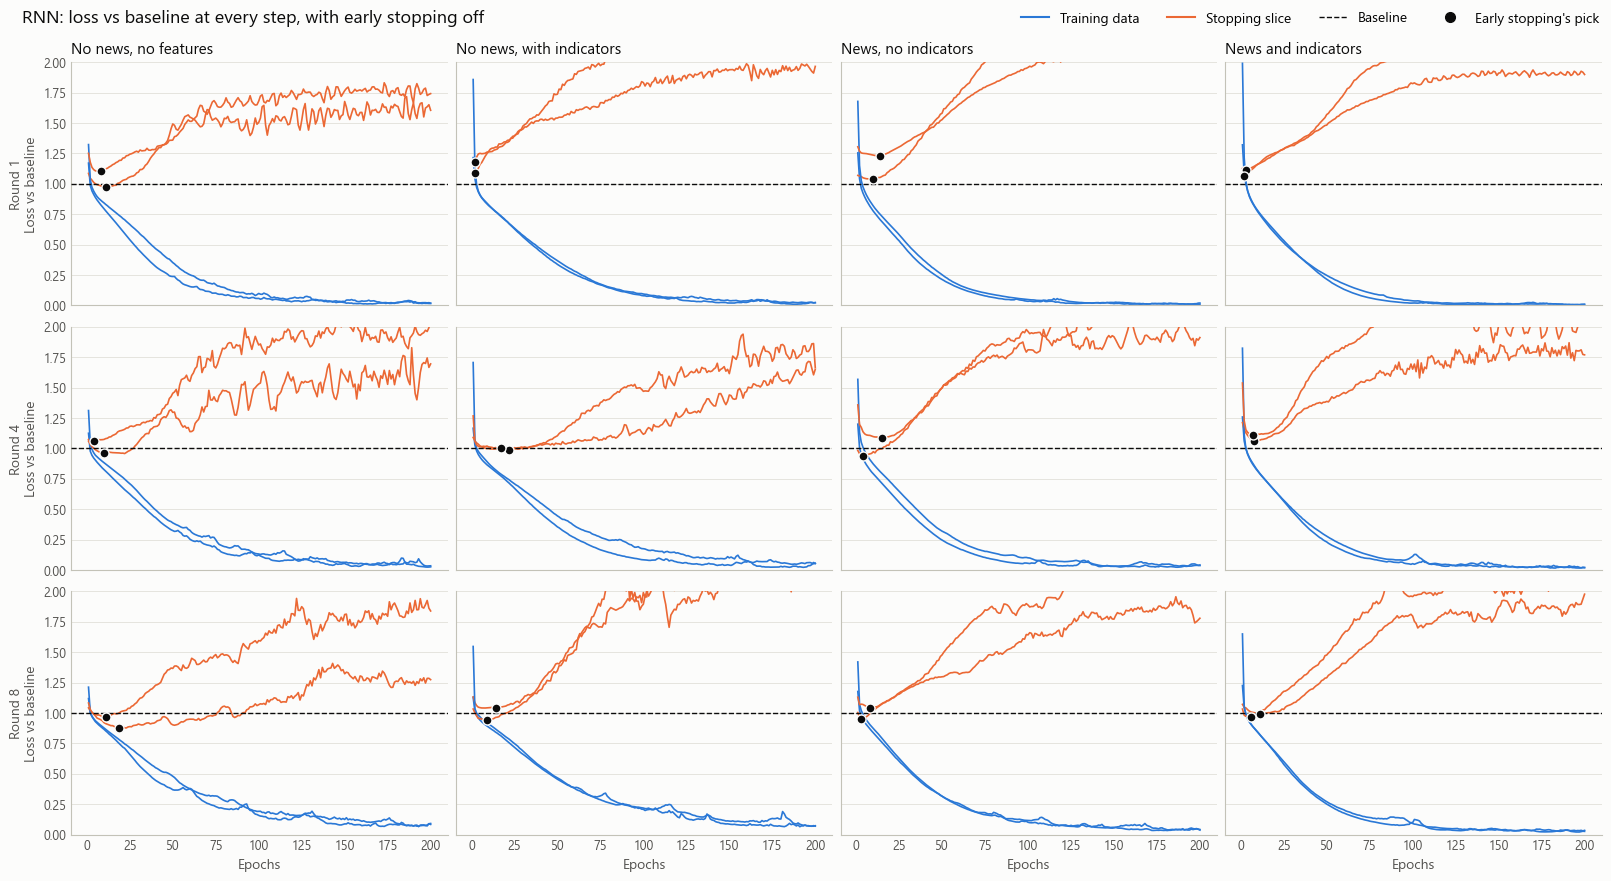

In [6]:
plot_learning_curves(curves, "RNN", title="RNN: loss vs baseline at every step, with early stopping off")

## LSTM curves

One line per seed, up to the full number of epochs.

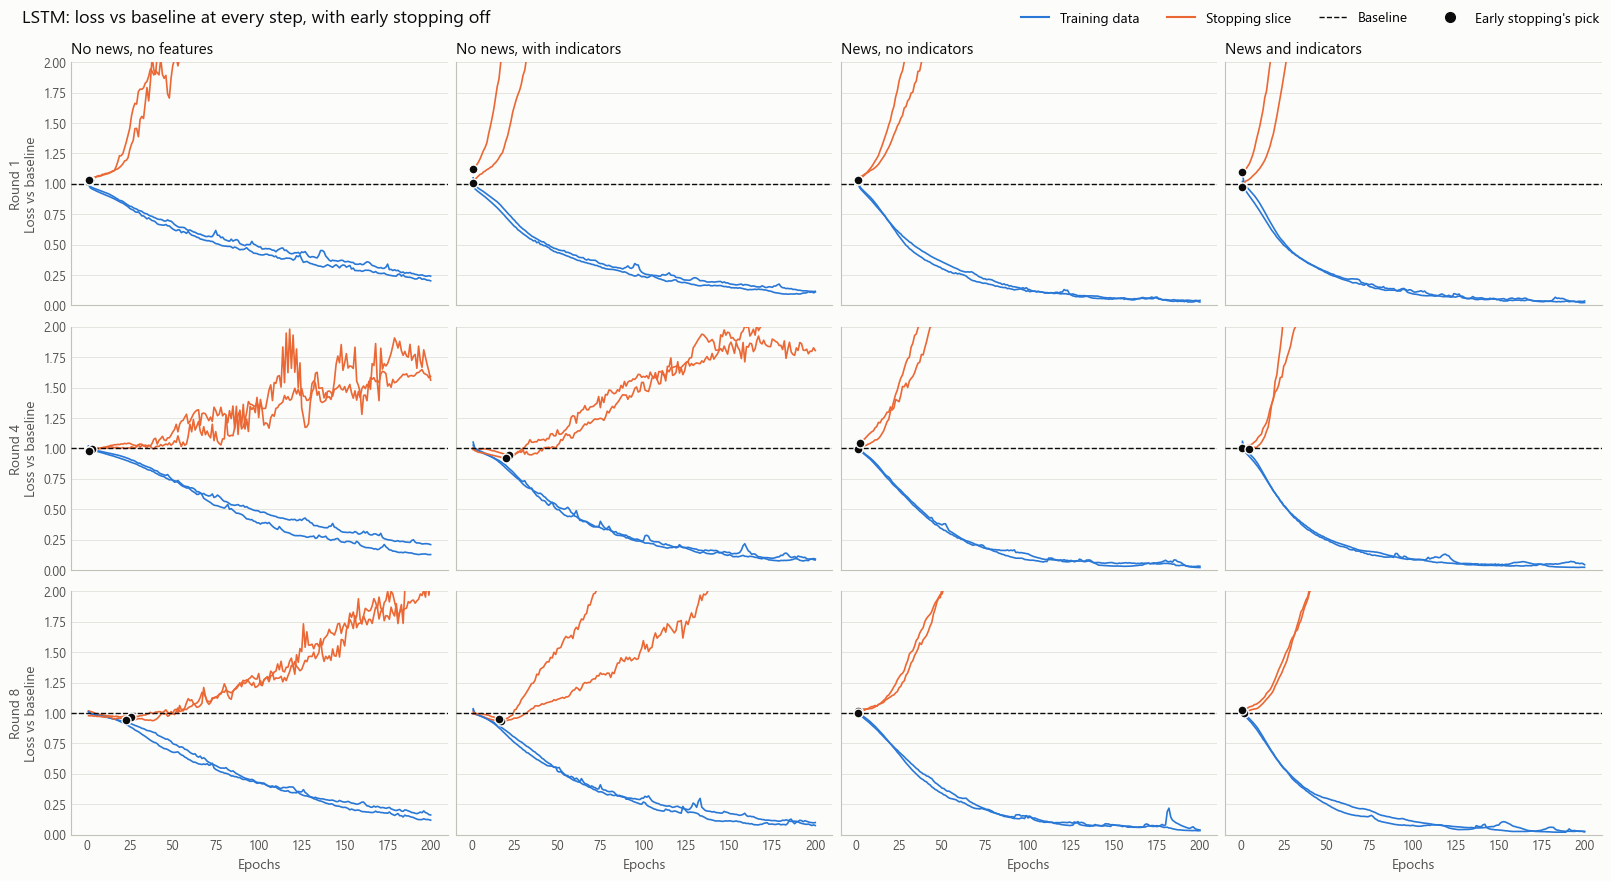

In [7]:
plot_learning_curves(curves, "LSTM", title="LSTM: loss vs baseline at every step, with early stopping off")

## XGBoost curves

One line per seed, up to the full number of trees.

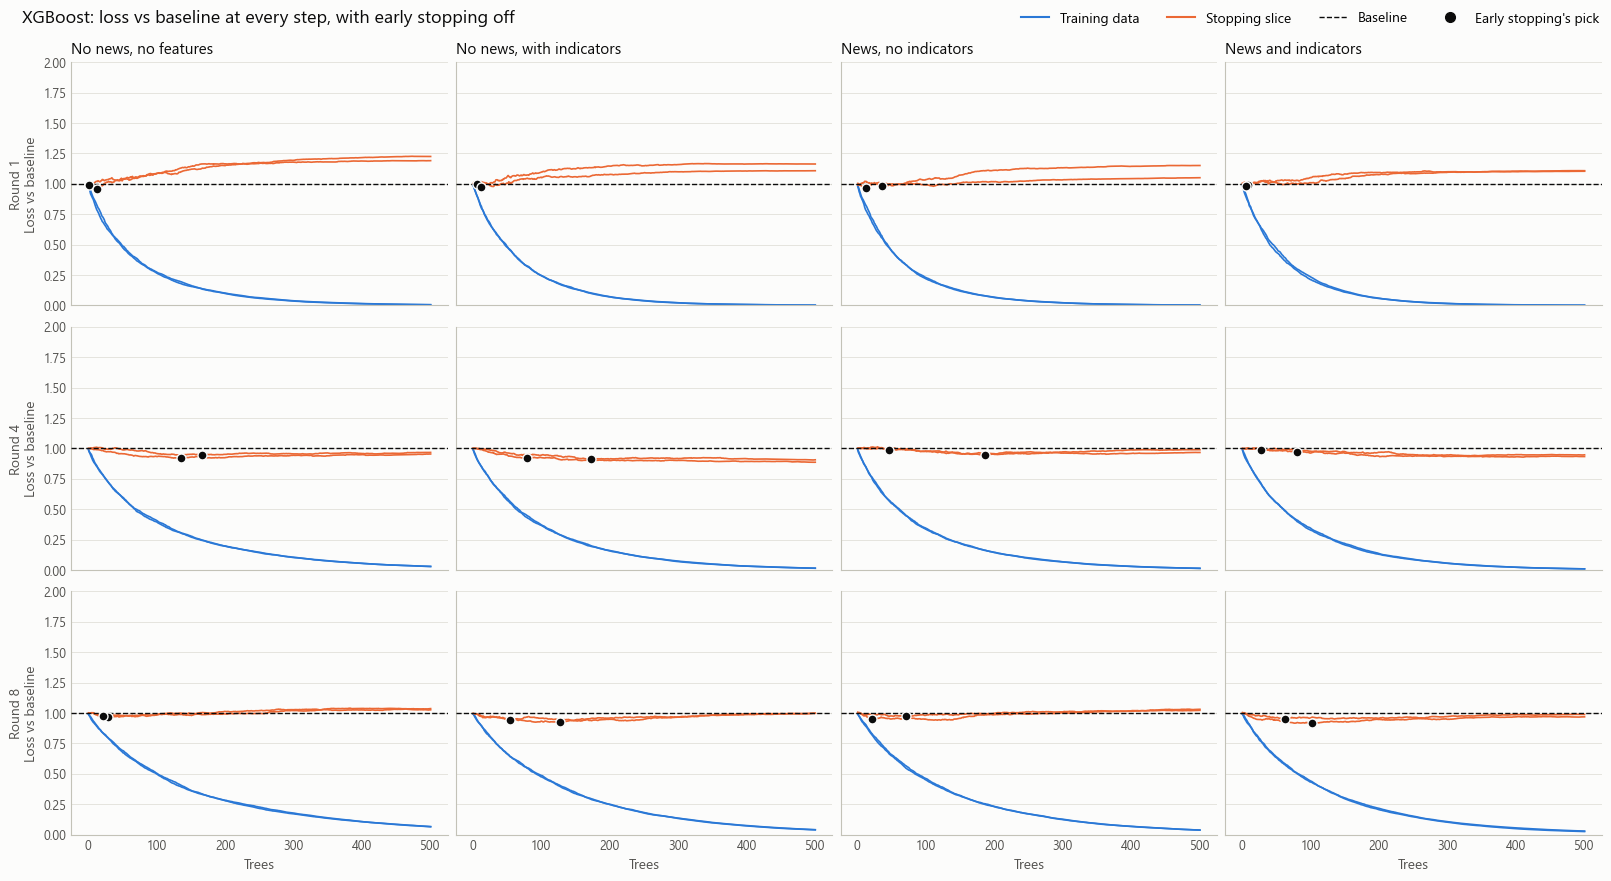

In [8]:
plot_learning_curves(curves, "XGBoost", title="XGBoost: loss vs baseline at every step, with early stopping off")